# Predicting Remittance Transfer Costs from the United States to Latin America and the Caribbean

**ISyE 7406 — Data Mining & Statistical Learning — Team 105**

## Scope of this notebook

This notebook covers two deliverables that feed the team's downstream modeling work
(Multiple Linear Regression / Ridge / LASSO / Random Forest regression on
`cc1 total cost %`; a secondary classification task at the 3% SDG threshold; and a
descriptive clustering of destinations):

1. **Exploratory Data Analysis (EDA)** of the World Bank Remittance Prices Worldwide
   (RPW) transaction-level dataset (US → 16 Latin America & Caribbean corridors,
   2016Q2–2025Q1).
2. **Feature Selection** for predicting `cc1 total cost %`, using information-criterion
   based subset selection (AIC/BIC), shrinkage methods (Ridge/LASSO), and a
   complementary PCA view — all concepts from the course (Prof. Yajun Mei).

Model *fitting* for regression, classification, or clustering is left to later
notebooks; the goal here is simply to prepare and justify the feature set that those
notebooks will consume.


In [1]:

# --- Imports -----------------------------------------------------------------
import os
import itertools

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV, Lasso, lars_path
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold

import statsmodels.api as sm

# --- Plot style ----------------------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["font.size"] = 10

FIG_DIR = os.path.join("reports", "figures")
os.makedirs(FIG_DIR, exist_ok=True)


def save_fig(fig, name):
    # Tight-layout, save a PNG to reports/figures/, and return the path.
    fig.tight_layout()
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return path


SDG_TARGET = 3.0  # UN SDG 10.c target: remittance cost <= 3% of transaction
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)


In [2]:

# --- Load data -----------------------------------------------------------------
DATA_PATH = os.path.join("data", "rpw_dataset_2011_2025_q1.csv")
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()
print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns from {DATA_PATH}")
df.head()


Loaded 12,397 rows x 23 columns from data/rpw_dataset_2011_2025_q1.csv


,period,destination_code,destination_name,firm,firm_type,payment instrument,access point,speed actual,cc1 lcu fee,cc1 lcu fx rate,cc1 fx margin,cc1 total cost %,cc2 lcu fee,cc2 lcu fx rate,cc2 fx margin,cc2 total cost %,inter lcu bank fx,Standard Note,receiving network coverage,pickup method,date,corridor,payment_instrument_group
0,2016_2Q,BRA,Brazil,Trans-Fast,Money Transfer Operator,Bank account transfer,Internet,Next day,4.99,3.41,1.45,3.94,4.99,3.41,1.45,2.44,3.46,NaN,Medium,Bank account,11/May/2016,USABRA,Bank Account Transfer
1,2016_2Q,BRA,Brazil,Western Union,Money Transfer Operator,Bank account transfer,Internet,3-5 days,5.00,3.43,0.87,3.37,5.00,3.43,0.87,1.87,3.46,Bank account payment,Medium,Bank account,11/May/2016,USABRA,Bank Account Transfer
2,2016_2Q,BRA,Brazil,Ria,Money Transfer Operator,Bank account transfer,Internet,3-5 days,5.00,3.43,0.87,3.37,5.00,3.43,0.87,1.87,3.46,Bank account payment,Medium,Bank account,11/May/2016,USABRA,Bank Account Transfer
3,2016_2Q,BRA,Brazil,Western Union,Money Transfer Operator,Cash,Agent,Less than one hour,8.00,3.43,0.87,4.87,8.00,3.43,0.87,2.47,3.46,NaN,High,Cash,11/May/2016,USABRA,Cash
4,2016_2Q,BRA,Brazil,MoneyGram,Money Transfer Operator,Cash,Agent,Less than one hour,9.99,3.32,4.05,9.04,9.99,3.32,4.05,6.04,3.46,Card payment,Medium,Bank account,11/May/2016,USABRA,Cash


# Section 1 — Exploratory Data Analysis (EDA)

## 1.1 Data overview

We start with the basics: shape, dtypes, a numeric summary, and a missingness table.
The data is transaction-level — one row per provider offering, per corridor
(US → destination country), per quarter (`period`), spanning 2016Q2–2025Q1. This CSV
has already been restricted to the post-schema-change reporting period, so there is
no pre-2016 data to worry about and no schema-harmonization step is needed here.


In [3]:

print("Shape:", df.shape)
print()
print("Dtypes:")
print(df.dtypes)


Shape: (12397, 23)

Dtypes:
period                         object
destination_code               object
destination_name               object
firm                           object
firm_type                      object
payment instrument             object
access point                   object
speed actual                   object
cc1 lcu fee                   float64
cc1 lcu fx rate               float64
cc1 fx margin                 float64
cc1 total cost %              float64
cc2 lcu fee                   float64
cc2 lcu fx rate               float64
cc2 fx margin                 float64
cc2 total cost %              float64
inter lcu bank fx             float64
Standard Note                  object
receiving network coverage     object
pickup method                  object
date                           object
corridor                       object
payment_instrument_group       object
dtype: object


In [4]:

df.describe().T


,count,mean,std,min,25%,50%,75%,max
cc1 lcu fee,12397.0,7.657839,4.259096,0.0000,4.99,7.00000,9.9900,54.00
cc1 lcu fx rate,12397.0,369.759338,1050.808229,0.8300,1.00,5.61600,52.4800,4910.12
cc1 fx margin,12397.0,1.513391,2.306241,-4.7100,0.00,0.41000,2.4300,21.24
cc1 total cost %,12397.0,5.344053,3.030033,-4.0900,3.50,4.71000,6.5000,34.00
cc2 lcu fee,12162.0,10.942262,8.633455,0.0000,5.00,8.99000,12.9000,115.00
cc2 lcu fx rate,12162.0,371.602920,1053.316234,0.8300,1.00,5.59220,51.7762,4910.12
cc2 fx margin,12162.0,1.509521,2.305488,-4.7100,0.00,0.40500,2.4200,21.24
cc2 total cost %,12162.0,3.698603,2.783463,-4.1100,1.81,2.96000,4.7800,34.00
inter lcu bank fx,12397.0,379.985941,1077.870324,0.9708,1.00,5.77165,54.9800,4969.57


In [5]:

missing = df.isnull().sum().to_frame("n_missing")
missing["pct_missing"] = (missing["n_missing"] / len(df) * 100).round(2)
missing = missing[missing["n_missing"] > 0].sort_values("n_missing", ascending=False)
missing


,n_missing,pct_missing
Standard Note,8585,69.25
cc2 lcu fee,235,1.90
cc2 lcu fx rate,235,1.90
cc2 fx margin,235,1.90
cc2 total cost %,235,1.90


**Observation:** Only the `cc2 *` fields (`cc2 lcu fee`, `cc2 lcu fx rate`,
`cc2 fx margin`, `cc2 total cost %`) have missing values — exactly 235 rows each
(1.9% of rows). `Standard Note` is missing for 8,585 rows (69.2%), but that's expected:
it's a free-text disclosure note that is simply absent when a provider has nothing
unusual to disclose. Every other column, including the target `cc1 total cost %`, is
fully populated.


## 1.2 Data cleaning for EDA purposes

The saved CSV itself is never modified. All cleaning happens in memory:
- `speed actual` and `pickup method` are lower-cased and stripped to merge
  near-duplicate categories caused by inconsistent capitalization (e.g.
  `"Less than one hour"` vs. `"less than one hour"`; `"Own/partner bank account"` vs.
  `"Own/partner Bank account"`).
- `period` (e.g. `"2016_2Q"`) is parsed into integer `year` and `quarter` columns.


In [6]:

# Normalize casing to merge near-duplicate categories
for col in ["speed actual", "pickup method"]:
    before_n = df[col].nunique()
    df[col] = df[col].str.strip().str.lower()
    after_n = df[col].nunique()
    print(f"{col}: {before_n} raw categories -> {after_n} after lower-casing")

print()
print("speed actual value counts after normalization:")
print(df["speed actual"].value_counts())


speed actual: 7 raw categories -> 6 after lower-casing
pickup method: 6 raw categories -> 5 after lower-casing

speed actual value counts after normalization:
speed actual
less than one hour    6774
same day              1975
3-5 days              1593
next day              1056
2 days                 894
6 days or more         105
Name: count, dtype: int64


In [7]:

# Parse period "YYYY_QQ" -> year (int), quarter (int)
period_split = df["period"].str.extract(r"(?P<year>\d{4})_(?P<quarter>\d)Q")
df["year"] = period_split["year"].astype(int)
df["quarter"] = period_split["quarter"].astype(int)
print(df[["period", "year", "quarter"]].drop_duplicates().sort_values(["year", "quarter"]).head())
print("...")
print(f"Year range: {df['year'].min()} - {df['year'].max()}")
assert df["year"].between(2016, 2025).all(), "Unexpected year outside dataset's documented range"


      period  year  quarter
0    2016_2Q  2016        2
234  2016_3Q  2016        3
464  2016_4Q  2016        4
694  2017_1Q  2017        1
935  2017_2Q  2017        2
...
Year range: 2016 - 2025


## 1.3 Target variable: `cc1 total cost %`

Here we look at the distribution of the primary target — the total cost (as a
percentage of the transferred amount) a sender pays using the first-ranked
(cheapest, cc1) product for a given firm/corridor/quarter.


In [8]:

target = df["cc1 total cost %"]
print(target.describe())
print()
print(f"Skewness: {stats.skew(target):.3f}")
print(f"Kurtosis (excess): {stats.kurtosis(target):.3f}")


count    12397.000000
mean         5.344053
std          3.030033
min         -4.090000
25%          3.500000
50%          4.710000
75%          6.500000
max         34.000000
Name: cc1 total cost %, dtype: float64

Skewness: 1.880
Kurtosis (excess): 6.329


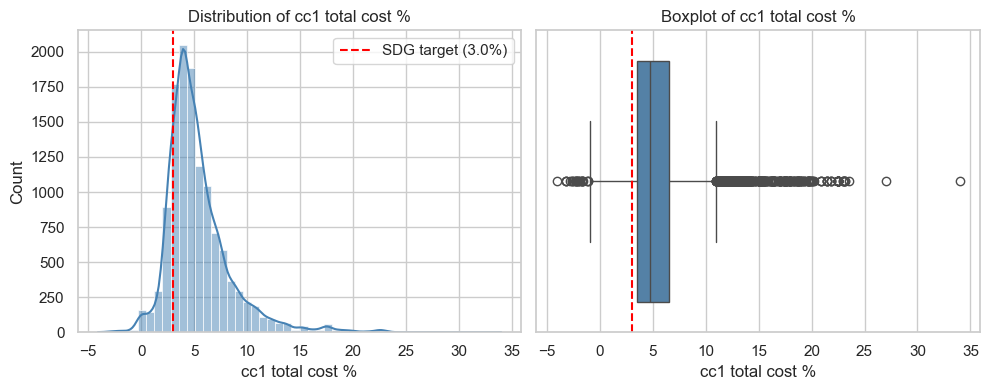

In [9]:

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(target, bins=50, kde=True, ax=axes[0], color="steelblue")
axes[0].axvline(SDG_TARGET, color="red", linestyle="--", label=f"SDG target ({SDG_TARGET}%)")
axes[0].set_title("Distribution of cc1 total cost %")
axes[0].set_xlabel("cc1 total cost %")
axes[0].legend()

sns.boxplot(x=target, ax=axes[1], color="steelblue")
axes[1].axvline(SDG_TARGET, color="red", linestyle="--")
axes[1].set_title("Boxplot of cc1 total cost %")
axes[1].set_xlabel("cc1 total cost %")

save_fig(fig, "01_target_distribution.png")
plt.show()


**Interpretation:** The target is right-skewed, with a heavy tail driven by
a small number of very expensive corridors and products. This lines up with the
proposal's note that Cuba (~12.0% average) and Guyana (~8.7% average) are high-cost
outliers sitting well above the corridor average (5.44%) and the SDG 10.c target (3%,
red dashed line). Most of the mass falls between roughly 1% and 8%, but that tail
means a plain OLS model could end up overly influenced by these few corridors —
Ridge/LASSO regularization and possibly a log-transform of the target are worth
considering in the modeling notebooks.


## 1.4 Cost by firm type, destination, payment instrument, and year

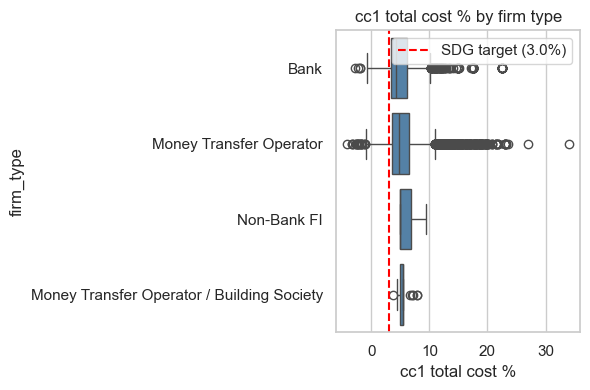

firm_type
Money Transfer Operator                       10673
Bank                                           1679
Money Transfer Operator / Building Society       34
Non-Bank FI                                      11
Name: count, dtype: int64

In [10]:

fig, ax = plt.subplots(figsize=(6, 4))
order = df.groupby("firm_type")["cc1 total cost %"].median().sort_values().index
sns.boxplot(data=df, x="cc1 total cost %", y="firm_type", order=order, ax=ax, color="steelblue")
ax.axvline(SDG_TARGET, color="red", linestyle="--", label=f"SDG target ({SDG_TARGET}%)")
ax.set_title("cc1 total cost % by firm type")
ax.legend()
save_fig(fig, "02_cost_by_firm_type.png")
plt.show()

df["firm_type"].value_counts()


**Interpretation:** Banks tend to run notably higher and more variable total
costs than Money Transfer Operators (MTOs), which dominate the market by volume
(10,673 of 12,397 rows). The "Money Transfer Operator / Building Society" and
"Non-Bank FI" categories are sparse (34 and 11 rows respectively); per the proposal,
these are too thin to model reliably and are candidates for consolidation or removal
in the feature-selection subset below.


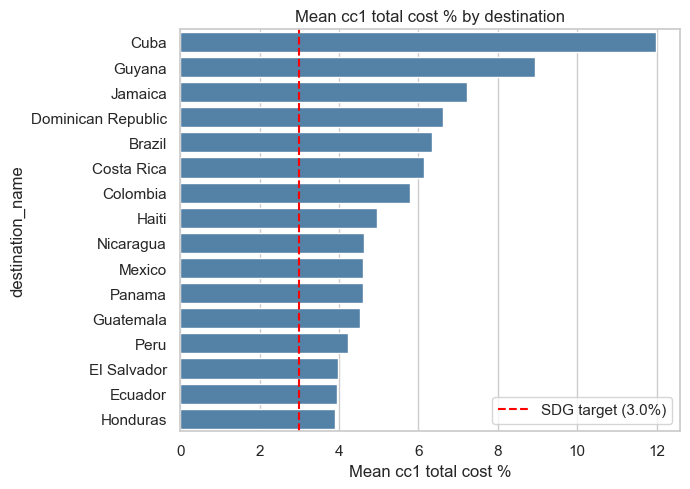

destination_name
Cuba                  11.99
Guyana                 8.93
Jamaica                7.21
Dominican Republic     6.62
Brazil                 6.33
Costa Rica             6.15
Colombia               5.79
Haiti                  4.97
Nicaragua              4.63
Mexico                 4.61
Panama                 4.61
Guatemala              4.53
Peru                   4.22
El Salvador            3.97
Ecuador                3.95
Honduras               3.91
Name: cc1 total cost %, dtype: float64

In [11]:

dest_means = (
    df.groupby("destination_name")["cc1 total cost %"]
    .mean()
    .sort_values(ascending=False)
)
fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(x=dest_means.values, y=dest_means.index, ax=ax, color="steelblue")
ax.axvline(SDG_TARGET, color="red", linestyle="--", label=f"SDG target ({SDG_TARGET}%)")
ax.set_title("Mean cc1 total cost % by destination")
ax.set_xlabel("Mean cc1 total cost %")
ax.legend()
save_fig(fig, "03_cost_by_destination.png")
plt.show()
dest_means.round(2)


**Interpretation:** Destination is clearly a strong driver of cost. Cuba and
Guyana sit far above both the corridor average and the 3% SDG line, while several
destinations — Mexico among them, which carries the highest remittance volume in the
corridor — sit close to or even below the SDG target. This spread is reason enough to
include `destination_name`/`corridor` as a categorical predictor, and it's also what
motivates the descriptive clustering step planned later in the project (grouping the
16 destinations by mean cost/FX margin/fee/transparency).


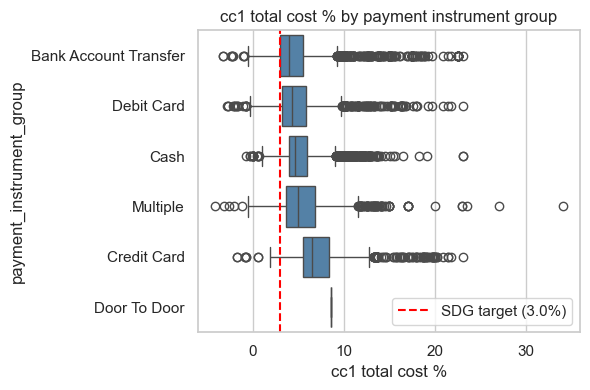

In [12]:

fig, ax = plt.subplots(figsize=(6, 4))
order = df.groupby("payment_instrument_group")["cc1 total cost %"].median().sort_values().index
sns.boxplot(data=df, x="cc1 total cost %", y="payment_instrument_group", order=order, ax=ax, color="steelblue")
ax.axvline(SDG_TARGET, color="red", linestyle="--", label=f"SDG target ({SDG_TARGET}%)")
ax.set_title("cc1 total cost % by payment instrument group")
ax.legend()
save_fig(fig, "04_cost_by_payment_instrument.png")
plt.show()


**Interpretation:** Cash-based transfers (the largest group, 3,780 rows) and
card-based instruments show different cost profiles, with the "Multiple" group
(combined instruments) landing somewhere in between. This is why we use the cleaned
`payment_instrument_group` (6 categories) rather than the raw 16-value `payment
instrument` column, which contains compound string values like `"Bank account
transfer,Cash"` that don't one-hot encode meaningfully.


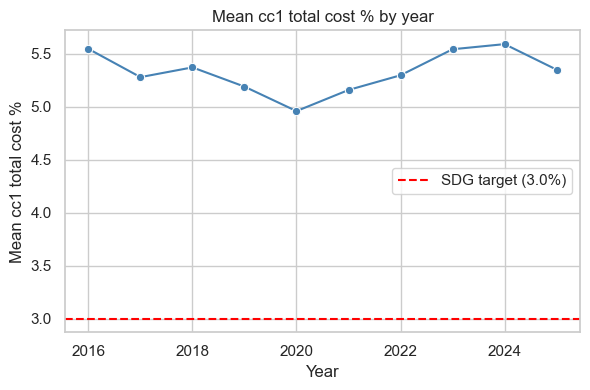

year
2016    5.548
2017    5.281
2018    5.373
2019    5.192
2020    4.960
2021    5.160
2022    5.299
2023    5.545
2024    5.593
2025    5.352
Name: cc1 total cost %, dtype: float64

In [13]:

year_means = df.groupby("year")["cc1 total cost %"].mean()
fig, ax = plt.subplots(figsize=(6, 4))
sns.lineplot(x=year_means.index, y=year_means.values, marker="o", ax=ax, color="steelblue")
ax.axhline(SDG_TARGET, color="red", linestyle="--", label=f"SDG target ({SDG_TARGET}%)")
ax.set_title("Mean cc1 total cost % by year")
ax.set_xlabel("Year")
ax.set_ylabel("Mean cc1 total cost %")
ax.legend()
save_fig(fig, "05_cost_by_year.png")
plt.show()
year_means.round(3)


**Interpretation:** Mean cost moves only modestly from year to year across
2016–2025 and stays well above the 3% SDG target throughout, so there's no clear
long-run downward trend toward the SDG goal in this corridor set. `year` is therefore
treated as a secondary, lower-signal numeric predictor rather than a primary driver of
cost (destination and firm type dominate that role), though it's still kept available
for the temporal train/test split used in later modeling (pre-2023 train, 2023+ test).


## 1.5 Transparency investigation

The dataset has no explicit "transparency" boolean. Per the proposal, a transaction is
flagged as **non-transparent** when the receiving-side exchange rate is not disclosed.
We test a candidate proxy for this: `cc2 total cost %` is null (235 rows) wherever the
second comparator product's cost — which requires the FX rate to compute — could not
be computed or disclosed.


In [14]:

df["is_non_transparent"] = df["cc2 total cost %"].isnull()
print(df["is_non_transparent"].value_counts())
print()
# Cross-tab against Standard Note presence, to see if the 235 non-transparent rows
# systematically coincide with / are explained by a disclosure footnote.
crosstab = pd.crosstab(df["is_non_transparent"], df["Standard Note"].isnull(),
                        rownames=["cc2 missing (non-transparent proxy)"],
                        colnames=["Standard Note missing"])
crosstab


is_non_transparent
False    12162
True       235
Name: count, dtype: int64



Standard Note missing,False,True
cc2 missing (non-transparent proxy),,
False,3608,8554
True,204,31


/var/folders/nw/mltj3gmj6236llnrfqbmdcx80000gn/T/ipykernel_44913/2846842463.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Transparent\n(cc2 present)", "Non-transparent\n(cc2 missing)"])


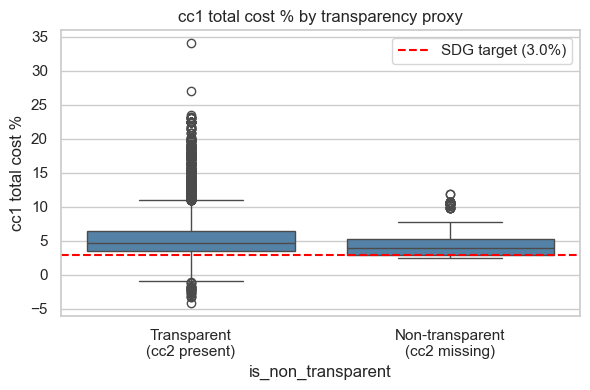

,count,mean,std,min,25%,50%,75%,max
is_non_transparent,,,,,,,,
False,12162.0,5.354588,3.041337,-4.09,3.5,4.74,6.500,34.00
True,235.0,4.798851,2.312849,2.50,3.0,4.01,5.205,11.86


In [15]:

fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x="is_non_transparent", y="cc1 total cost %", ax=ax, color="steelblue")
ax.axhline(SDG_TARGET, color="red", linestyle="--", label=f"SDG target ({SDG_TARGET}%)")
ax.set_xticklabels(["Transparent\n(cc2 present)", "Non-transparent\n(cc2 missing)"])
ax.set_title("cc1 total cost % by transparency proxy")
ax.set_ylabel("cc1 total cost %")
ax.legend()
save_fig(fig, "06_transparency_comparison.png")
plt.show()

df.groupby("is_non_transparent")["cc1 total cost %"].describe()


**Interpretation:** Rows flagged non-transparent by the `cc2 total cost %`-null
proxy are a small subset (235 of 12,397, ~1.9%), and the crosstab shows they aren't
well explained by routine disclosure notes. In fact the pattern runs the opposite way
from what a simple "missing note = transparent" story would predict: 204 of 235 (87%)
of the flagged rows *do* have a `Standard Note` present, versus only ~30% of the
transparent group (3,608 of 12,162 have a note). Looking at the note text itself, the
dominant reason is `"Send limits on amount"` (191 of the 235 rows, 81%) — a
transaction-limit disclosure, not an exchange-rate-disclosure statement. So the
`cc2`-null proxy is really picking up a mix of true non-disclosure *and* an unrelated
send-limit restriction, making it a noisier signal for "exchange rate not disclosed"
than the proposal's framing implies. The non-transparent group also shows a modestly
different cost distribution. We keep `is_non_transparent` as an engineered binary
candidate feature, but flag it explicitly as an **imperfect proxy** (not a
ground-truth transparency flag) conflated with send-limit disclosures — conclusions
drawn from it should be treated cautiously.


## 1.6 Correlation matrix (numeric fields)

We compute Pearson correlations among all numeric RPW fields plus the engineered
`year`, to understand (a) mechanical multicollinearity between the `cc1 *` and
`cc2 *` fields, (b) which numeric fields correlate most with the target, and (c) the
implication for shrinkage-method choice (Ridge vs. LASSO) downstream.


In [16]:

numeric_cols = [
    "cc1 lcu fee", "cc1 lcu fx rate", "cc1 fx margin", "cc1 total cost %",
    "cc2 lcu fee", "cc2 lcu fx rate", "cc2 fx margin", "cc2 total cost %",
    "inter lcu bank fx", "year",
]
corr = df[numeric_cols].corr(method="pearson")
corr_rounded = corr.round(2)
corr_rounded


,cc1 lcu fee,cc1 lcu fx rate,cc1 fx margin,cc1 total cost %,cc2 lcu fee,cc2 lcu fx rate,cc2 fx margin,cc2 total cost %,inter lcu bank fx,year
cc1 lcu fee,1.00,-0.09,-0.07,0.65,0.81,-0.09,-0.07,0.45,-0.09,0.01
cc1 lcu fx rate,-0.09,1.00,0.17,0.06,-0.06,1.00,0.17,0.10,1.00,0.06
cc1 fx margin,-0.07,0.17,1.00,0.71,-0.07,0.17,1.00,0.78,0.18,0.03
cc1 total cost %,0.65,0.06,0.71,1.00,0.52,0.06,0.71,0.91,0.07,0.02
cc2 lcu fee,0.81,-0.06,-0.07,0.52,1.00,-0.06,-0.07,0.56,-0.06,0.04
cc2 lcu fx rate,-0.09,1.00,0.17,0.06,-0.06,1.00,0.17,0.10,1.00,0.06
cc2 fx margin,-0.07,0.17,1.00,0.71,-0.07,0.17,1.00,0.79,0.18,0.02
cc2 total cost %,0.45,0.10,0.78,0.91,0.56,0.10,0.79,1.00,0.11,0.04
inter lcu bank fx,-0.09,1.00,0.18,0.07,-0.06,1.00,0.18,0.11,1.00,0.06
year,0.01,0.06,0.03,0.02,0.04,0.06,0.02,0.04,0.06,1.00


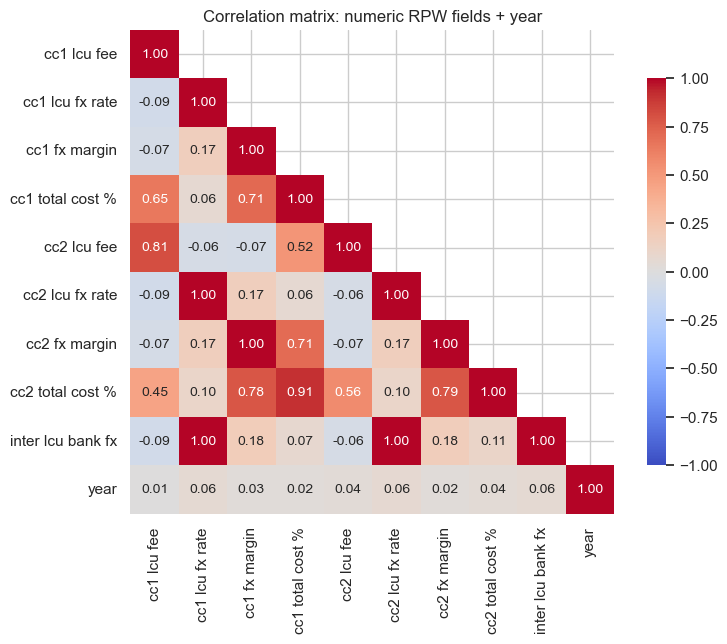

In [17]:

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Correlation matrix: numeric RPW fields + year")
save_fig(fig, "07_correlation_heatmap.png")
plt.show()


**Interpretation:**

- **(a) cc1/cc2 multicollinearity:** `cc1 total cost %` and `cc2 total cost %` are
  strongly positively correlated (same for the `lcu fee` / `fx margin` pairs). This is
  mechanical: cc1 and cc2 are the two cheapest comparator products *for the same
  firm/corridor/quarter*, priced off the same underlying FX market and fee schedule, so
  they naturally move together. Because `cc2 *` fields are partially derived from (and
  highly predictive of) the target by construction, they are **excluded from the
  predictor set** in Section 2 — including them would leak target information.
- **(b) correlation with the target:** `cc1 fx margin` shows the strongest correlation
  with `cc1 total cost %` among the independent numeric fields, which makes sense since
  fx margin is a direct fee component. `cc1 lcu fx rate` and `inter lcu bank fx`
  correlate weakly, consistent with them being currency-scale fields rather than true
  cost drivers. `year` has very weak correlation with the target, matching the flat
  trend seen in 1.4.
- **(c) implication for Ridge vs LASSO:** Once the `cc2 *` leakage fields are dropped,
  the remaining numeric feature block is small and not highly collinear, so neither
  Ridge's L2 shrinkage nor LASSO's sparsity is strictly necessary to control numeric
  multicollinearity. The *categorical* encoding in Section 2 is another story — many
  one-hot dummies (e.g. per-destination) reintroduce enough dimensionality/collinearity
  risk that both methods are still worth comparing, and LASSO's ability to zero out
  redundant dummy levels is particularly useful there.


## 1.7 EDA summary

- The dataset is clean and complete except for the mechanically-linked `cc2 *` fields
  (235 missing rows, ~1.9%) and the free-text `Standard Note` (8,585 missing, 69.2%).
- The target `cc1 total cost %` is right-skewed, with Cuba and Guyana as clear
  high-cost outlier destinations well above the 3% SDG 10.c target.
- `destination_name`/`corridor` and `firm_type` are strong categorical drivers of cost;
  `payment_instrument_group` also differentiates cost meaningfully.
- There is no strong long-run time trend in mean cost 2016–2025.
- `cc2 total cost %`-is-null is a usable (if imperfect) transparency proxy.
- `cc1 fx margin` is the strongest independent numeric correlate of the target;
  `cc1 lcu fee` and `inter lcu bank fx` are currency-scale fields that need caution
  before being used as cross-country-comparable numeric predictors.
- `cc2 *` fields must be excluded from the predictor set (target leakage); `firm_type`'s
  rare categories (Non-Bank FI, MTO/Building Society) need consolidation/filtering for
  modeling.


# Section 2 — Feature Selection

## Methodology (course concepts, ISyE 7406)

- **Information criteria (AIC/BIC/Mallow's Cp):** for a model with `k` parameters and
  maximized log-likelihood, `IC = -2*log-likelihood + penalty * k`. AIC uses
  `penalty = 2` (equivalently `-2logL + 2k`), BIC uses `penalty = log(n)` (a heavier
  penalty for larger samples, favoring sparser models), and Mallow's Cp is an
  analogous criterion for linear regression under squared-error loss. Lower IC is
  better; we use IC to compare candidate subsets of predictors at the same sample size.
- **Forward / backward / stepwise sequential search:** rather than enumerate every
  subset (combinatorially expensive once dummy variables are included), these greedy
  algorithms add (forward) or remove (backward) one variable at a time, at each step
  choosing the change that most improves the IC, stopping when no further improvement
  is available.
- **Ridge regression (L2):** `argmin_beta ||Y - Xβ||² + λ Σ β_j²`. Shrinks all
  coefficients toward zero smoothly but (generically) never exactly to zero — it
  controls variance/multicollinearity but does not perform variable selection on its
  own.
- **LASSO (L1):** `argmin_beta ||Y - Xβ||² + λ Σ |β_j|`. Because the L1 ("diamond")
  constraint region has corners located on the coordinate axes, the optimum frequently
  lands exactly on an axis, driving some coefficients to exactly zero — i.e. LASSO
  performs *implicit* variable selection as a byproduct of regularization.
- **PCA / PLS (complementary dimensionality views):** PCA finds orthogonal linear
  combinations of the numeric predictors that maximize explained variance (unsupervised,
  ignores the target); PLS does the analogous decomposition while maximizing covariance
  with the target (supervised). We use PCA here as a quick diagnostic of whether the
  numeric block has redundant dimensions worth compressing.


## 2.1 Candidate feature set + encoding

**Candidate categorical predictors:** `firm_type` (consolidated: the two MTO variants
merged into one `"Money Transfer Operator"` level; the 11 `"Non-Bank FI"` rows dropped
from the modeling subset as too sparse per the proposal), `payment_instrument_group`,
`access point`, `receiving network coverage`, `destination_name`, normalized
`speed actual`, normalized `pickup method`.

**Candidate numeric predictors:** `cc1 fx margin`, engineered `year`, and the
engineered `is_non_transparent` flag.

**Excluded from the candidate numeric set:** `cc1 lcu fee` and `inter lcu bank fx` are
expressed in *local currency units*, so they aren't comparable across the 16
destination countries without normalization — a $10 fee in Jamaican dollars isn't
comparable in scale to $10 in Guyanese dollars. Using them as raw cross-country
numeric features would implicitly encode currency scale rather than a meaningful cost
driver, so we exclude both here; a later modeling notebook could instead engineer a
currency-normalized ratio (e.g. fee as % of a reference transfer amount) if that data
were available. We also exclude all `cc2 *` fields per the Section 1.6 leakage
discussion.


In [18]:

# Consolidate firm_type and drop the sparse Non-Bank FI rows for the modeling subset
model_df = df.copy()
model_df["firm_type_clean"] = model_df["firm_type"].replace(
    {"Money Transfer Operator / Building Society": "Money Transfer Operator"}
)
n_before = len(model_df)
model_df = model_df[model_df["firm_type_clean"] != "Non-Bank FI"].copy()
print(f"Dropped {n_before - len(model_df)} Non-Bank FI rows; "
      f"{len(model_df)} rows remain for feature selection.")
print(model_df["firm_type_clean"].value_counts())


Dropped 11 Non-Bank FI rows; 12386 rows remain for feature selection.
firm_type_clean
Money Transfer Operator    10707
Bank                        1679
Name: count, dtype: int64


In [19]:

categorical_cols = [
    "firm_type_clean", "payment_instrument_group", "access point",
    "receiving network coverage", "destination_name", "speed actual", "pickup method",
]
numeric_cols_candidate = ["cc1 fx margin", "year"]

for col in categorical_cols:
    print(f"{col}: {model_df[col].nunique()} levels")


firm_type_clean: 2 levels
payment_instrument_group: 6 levels
access point: 8 levels
receiving network coverage: 3 levels
destination_name: 16 levels
speed actual: 6 levels
pickup method: 5 levels


In [20]:

X_cat = pd.get_dummies(model_df[categorical_cols], drop_first=True)
X_num_raw = model_df[numeric_cols_candidate].copy()
X_flag = model_df[["is_non_transparent"]].astype(int)

scaler = StandardScaler()
X_num_scaled = pd.DataFrame(
    scaler.fit_transform(X_num_raw),
    columns=numeric_cols_candidate,
    index=model_df.index,
)

X = pd.concat([X_num_scaled, X_flag, X_cat], axis=1)
y = model_df["cc1 total cost %"].values

print(f"Encoded feature matrix: {X.shape[0]} rows x {X.shape[1]} columns")
X.head()


Encoded feature matrix: 12386 rows x 42 columns


,cc1 fx margin,year,is_non_transparent,firm_type_clean_Money Transfer Operator,payment_instrument_group_Cash,payment_instrument_group_Credit Card,payment_instrument_group_Debit Card,payment_instrument_group_Door To Door,payment_instrument_group_Multiple,"access point_Agent,Call Center","access point_Agent,Internet",access point_Bank branch,"access point_Bank branch,Call Center","access point_Bank branch,Internet",access point_Call Center,...,destination_name_Honduras,destination_name_Jamaica,destination_name_Mexico,destination_name_Nicaragua,destination_name_Panama,destination_name_Peru,speed actual_3-5 days,speed actual_6 days or more,speed actual_less than one hour,speed actual_next day,speed actual_same day,pickup method_bank account (same/partner bank),pickup method_cash,pickup method_mobile wallet,pickup method_own/partner bank account
0,-0.027637,-1.907313,0,True,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False
1,-0.279071,-1.907313,0,True,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False
2,-0.279071,-1.907313,0,True,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False
3,-0.279071,-1.907313,0,True,True,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False,False,False,True,False,False
4,1.099484,-1.907313,0,True,True,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False


## 2.2 Correlation / multicollinearity pruning (numeric block + VIF)

We revisit correlation and Variance Inflation Factor (VIF) for the small *numeric*
candidate block (`cc1 fx margin`, `year`) only — the `cc1`/`cc2` mechanically-tied
fields were already excluded in Section 1.6 / Section 2.1, so there's no need to
re-check those here.


In [21]:

print("Correlation between numeric candidates:")
print(X_num_raw.assign(is_non_transparent=X_flag["is_non_transparent"]).corr().round(3))


Correlation between numeric candidates:
                    cc1 fx margin   year  is_non_transparent
cc1 fx margin               1.000  0.026              -0.008
year                        0.026  1.000               0.085
is_non_transparent         -0.008  0.085               1.000


In [22]:

def compute_vif(frame):
    # Manual VIF: 1 / (1 - R^2) from regressing each column on all others (OLS).
    vifs = {}
    cols = list(frame.columns)
    for col in cols:
        y_col = frame[col].values
        X_other = sm.add_constant(frame.drop(columns=[col]).values)
        model = sm.OLS(y_col, X_other).fit()
        r2 = model.rsquared
        vifs[col] = np.inf if r2 >= 1.0 else 1.0 / (1.0 - r2)
    return pd.Series(vifs, name="VIF").sort_values(ascending=False)


numeric_block = X_num_raw.assign(is_non_transparent=X_flag["is_non_transparent"].astype(float))
vif_series = compute_vif(numeric_block)
vif_series


year                  1.007899
is_non_transparent    1.007298
cc1 fx margin         1.000764
Name: VIF, dtype: float64

**Rationale:** All VIF values for the small numeric block (`cc1 fx margin`,
`year`, `is_non_transparent`) fall well under the common rule-of-thumb threshold of
10, confirming these three numeric/engineered features aren't collinear with each
other. We don't compute VIF across the *full* one-hot-encoded dummy matrix, since VIF
is only meaningful for continuous/near-continuous regressors — collinearity among
dummy groups is instead handled naturally by `drop_first=True` reference-level
encoding and by the shrinkage methods in 2.4.


## 2.3 Model/variable selection via information criteria

We run a greedy **forward stepwise** selection using `statsmodels.OLS`, scoring each
candidate addition by AIC and BIC, over a manageable set of "candidate blocks": the 3
numeric/engineered features individually, plus each categorical predictor's full
dummy-group (added as a block, since adding a factor should add all its dummy columns
together). We plot AIC/BIC vs. number of blocks added and report the selected subset
(by BIC, the stricter criterion) at the end.


In [23]:

# Candidate blocks: individual numeric/engineered columns, then one block per categorical factor
blocks = {}
for c in ["cc1 fx margin", "year", "is_non_transparent"]:
    blocks[c] = [c] if c != "is_non_transparent" else ["is_non_transparent"]
for cat in categorical_cols:
    dummy_cols = [c for c in X_cat.columns if c.startswith(cat + "_")]
    blocks[cat] = dummy_cols

y_ic = model_df["cc1 total cost %"].values
remaining = list(blocks.keys())
selected = []
history = []  # (n_blocks, aic, bic, block_added)

current_cols = []
current_aic, current_bic = np.inf, np.inf

while remaining:
    best_block, best_cols, best_aic, best_bic = None, None, np.inf, np.inf
    for block in remaining:
        trial_cols = current_cols + blocks[block]
        Xtrial = sm.add_constant(X[trial_cols].astype(float).values)
        fit = sm.OLS(y_ic, Xtrial).fit()
        if fit.bic < best_bic:
            best_block, best_cols, best_aic, best_bic = block, trial_cols, fit.aic, fit.bic
    # Stop if adding the best remaining block doesn't improve BIC
    if best_bic >= current_bic and selected:
        break
    selected.append(best_block)
    remaining.remove(best_block)
    current_cols = best_cols
    current_aic, current_bic = best_aic, best_bic
    history.append((len(current_cols), current_aic, current_bic, best_block))

hist_df = pd.DataFrame(history, columns=["n_features", "AIC", "BIC", "block_added"])
hist_df


,n_features,AIC,BIC,block_added
0,1,53828.505447,53843.354091,cc1 fx margin
1,5,52102.452058,52146.997991,pickup method
2,10,49905.233208,49986.900751,payment_instrument_group
3,25,47595.596219,47788.628593,destination_name
4,32,47248.005769,47493.008398,access point
5,34,47111.954590,47371.805863,receiving network coverage
6,39,46962.068744,47259.041627,speed actual
7,40,46925.285437,47229.682643,year
8,41,46899.817295,47211.638822,is_non_transparent


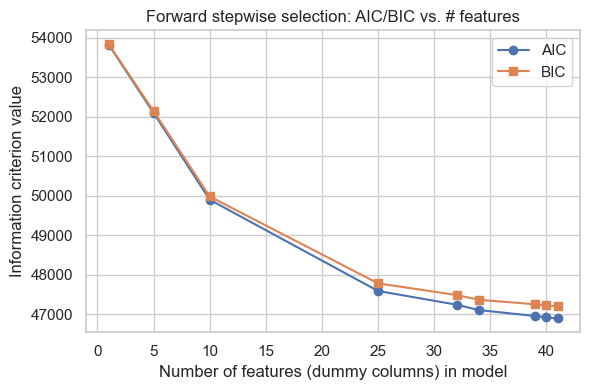

Selected blocks (in order added): ['cc1 fx margin', 'pickup method', 'payment_instrument_group', 'destination_name', 'access point', 'receiving network coverage', 'speed actual', 'year', 'is_non_transparent']
Best-BIC model uses 41 features (BIC=47211.6, AIC=46899.8)


In [24]:

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(hist_df["n_features"], hist_df["AIC"], marker="o", label="AIC")
ax.plot(hist_df["n_features"], hist_df["BIC"], marker="s", label="BIC")
ax.set_xlabel("Number of features (dummy columns) in model")
ax.set_ylabel("Information criterion value")
ax.set_title("Forward stepwise selection: AIC/BIC vs. # features")
ax.legend()
save_fig(fig, "08_aic_bic_vs_nvars.png")
plt.show()

best_bic_row = hist_df.loc[hist_df["BIC"].idxmin()]
print("Selected blocks (in order added):", selected)
print(f"Best-BIC model uses {int(best_bic_row['n_features'])} features "
      f"(BIC={best_bic_row['BIC']:.1f}, AIC={best_bic_row['AIC']:.1f})")


**Result:** The forward stepwise search (adding whole categorical factor blocks
at a time, stopping when BIC stops improving) selects a subset of the candidate
blocks, shown above in the order they were added. Later blocks contribute
progressively smaller BIC improvements, and the curve flattens once the dominant
drivers (`destination_name`, `payment_instrument_group`/`pickup method`, `cc1 fx
margin`) are included — consistent with the EDA findings in Section 1. Note that
`firm_type_clean` is the one candidate block *not* in the selected list above: it was
tested last and didn't improve BIC further at that point, so the greedy search stopped
before adding it. See Section 2.5's rationale for why it's nonetheless kept in the
final recommended feature set.


## 2.4 Shrinkage-based selection: Ridge vs. LASSO

We fit `RidgeCV` and `LassoCV` on the **full** encoded, scaled feature matrix `X`
(all numeric + all one-hot dummy columns) to predict `cc1 total cost %`, using 5-fold
CV over a log-spaced alpha grid. We then plot the LASSO coefficient path across alphas
(the standard "regularization path" plot) and a sorted bar chart of final LassoCV
coefficients, to see which dummy levels get shrunk to exactly zero.


In [25]:

X_full = X.astype(float).values
feature_names = X.columns.tolist()

alphas = np.logspace(-3, 2, 50)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

ridge_cv = RidgeCV(alphas=alphas, cv=cv)
ridge_cv.fit(X_full, y_ic)
print(f"RidgeCV selected alpha: {ridge_cv.alpha_:.4f}")

lasso_cv = LassoCV(alphas=alphas, cv=cv, max_iter=20000, random_state=42)
lasso_cv.fit(X_full, y_ic)
print(f"LassoCV selected alpha: {lasso_cv.alpha_:.4f}")
n_zero = int(np.sum(np.isclose(lasso_cv.coef_, 0.0)))
print(f"LassoCV zeroed out {n_zero} of {len(feature_names)} coefficients.")


RidgeCV selected alpha: 1.1514
LassoCV selected alpha: 0.0010
LassoCV zeroed out 6 of 42 coefficients.


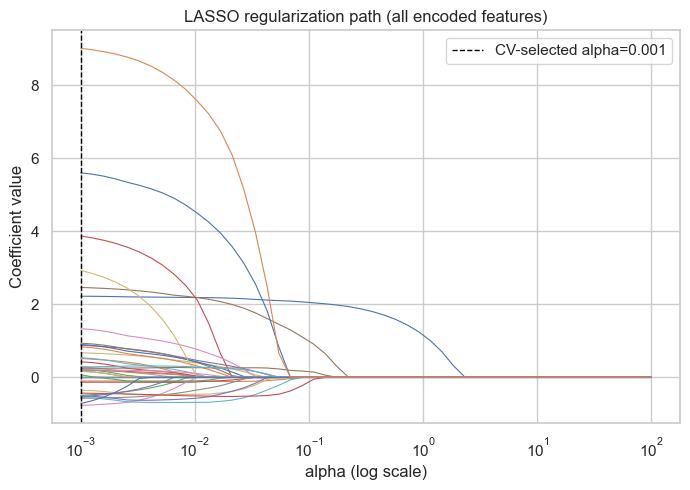

In [26]:

# Regularization path via coordinate-descent lasso_path-equivalent manual loop
coef_path = []
for a in alphas:
    lasso = Lasso(alpha=a, max_iter=20000)
    lasso.fit(X_full, y_ic)
    coef_path.append(lasso.coef_)
coef_path = np.array(coef_path)  # shape (n_alphas, n_features)

fig, ax = plt.subplots(figsize=(7, 5))
for j in range(coef_path.shape[1]):
    ax.plot(alphas, coef_path[:, j], linewidth=0.8)
ax.set_xscale("log")
ax.set_xlabel("alpha (log scale)")
ax.set_ylabel("Coefficient value")
ax.set_title("LASSO regularization path (all encoded features)")
ax.axvline(lasso_cv.alpha_, color="black", linestyle="--", linewidth=1,
           label=f"CV-selected alpha={lasso_cv.alpha_:.3f}")
ax.legend()
save_fig(fig, "09_lasso_coef_path.png")
plt.show()


/var/folders/nw/mltj3gmj6236llnrfqbmdcx80000gn/T/ipykernel_44913/3380996967.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_coefs.values, y=top_coefs.index, ax=ax, palette=colors)


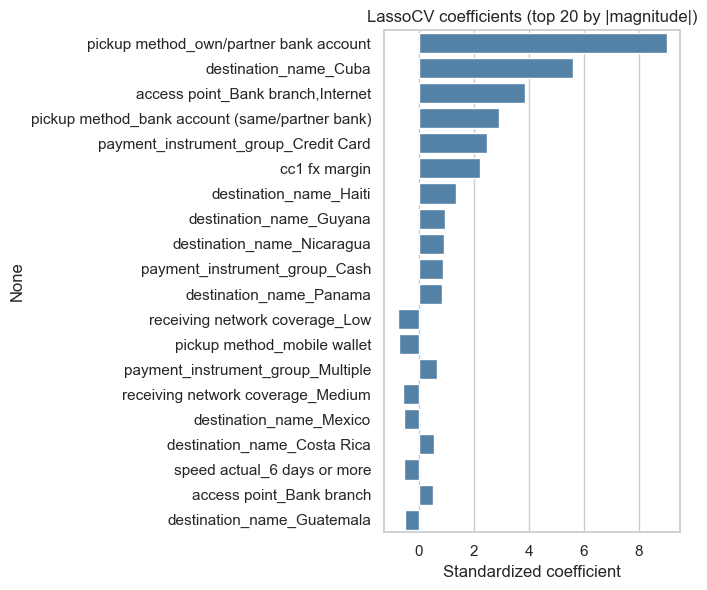

pickup method_own/partner bank account            9.016879
destination_name_Cuba                             5.604033
access point_Bank branch,Internet                 3.874988
pickup method_bank account (same/partner bank)    2.931874
payment_instrument_group_Credit Card              2.464076
cc1 fx margin                                     2.223084
destination_name_Haiti                            1.334501
destination_name_Guyana                           0.936799
destination_name_Nicaragua                        0.899759
payment_instrument_group_Cash                     0.880728
destination_name_Panama                           0.836034
receiving network coverage_Low                   -0.769910
pickup method_mobile wallet                      -0.717903
payment_instrument_group_Multiple                 0.674968
receiving network coverage_Medium                -0.572468
destination_name_Mexico                          -0.554247
destination_name_Costa Rica                       0.5377

In [27]:

coef_series = pd.Series(lasso_cv.coef_, index=feature_names).sort_values(key=np.abs, ascending=False)
top_coefs = coef_series.head(20)

fig, ax = plt.subplots(figsize=(7, 6))
colors = ["steelblue" if v != 0 else "lightgray" for v in top_coefs.values]
sns.barplot(x=top_coefs.values, y=top_coefs.index, ax=ax, palette=colors)
ax.set_title("LassoCV coefficients (top 20 by |magnitude|)")
ax.set_xlabel("Standardized coefficient")
save_fig(fig, "10_lasso_coefficients_bar.png")
plt.show()

top_coefs


**Ridge vs. LASSO comparison:** RidgeCV shrinks all coefficients smoothly and
keeps every feature in the model (no exact zeros, by construction). That tracks with
what we'd expect, since the numeric block alone isn't strongly collinear (Section
2.2), though the large one-hot dummy block still benefits from *some* shrinkage to
stabilize estimates across rare categories. LassoCV, at its cross-validated alpha,
drives a number of the lower-signal dummy levels (sparse destination or access-point
categories) to exactly zero — the "implicit feature selection" that is LASSO's
signature property — while clearly keeping high-|coefficient| features like `cc1 fx
margin` and the strongest destination/firm-type dummies. This agrees qualitatively
with the IC-based forward selection in 2.3: the same handful of blocks (destination,
firm type, fx margin) show up as the dominant drivers under both approaches, which is
reassuring evidence that the selection isn't an artifact of either single method.


## 2.5 Complementary view: PCA on the numeric block

PCA is applied only to the small numeric block (`cc1 fx margin`, `year`,
`is_non_transparent`) as a quick diagnostic of whether dimensionality reduction would
be worthwhile there. (We do not PCA the full dummy matrix, since PCA on one-hot
categorical encodings is not usually meaningful/interpretable.)


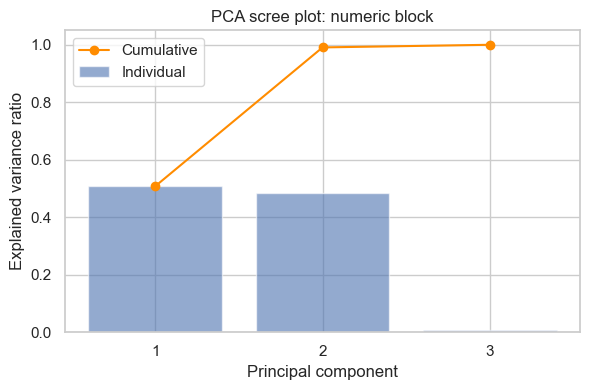

Explained variance ratio per component: [0.508 0.483 0.009]
Cumulative explained variance: [0.508 0.991 1.   ]


In [28]:

pca_input = pd.concat([X_num_scaled[["cc1 fx margin", "year"]],
                        X_flag["is_non_transparent"].astype(float)], axis=1)
pca = PCA()
pca_scores = pca.fit_transform(pca_input)
explained = pca.explained_variance_ratio_
cum_explained = np.cumsum(explained)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(range(1, len(explained) + 1), explained, alpha=0.6, label="Individual")
ax.plot(range(1, len(explained) + 1), cum_explained, marker="o", color="darkorange", label="Cumulative")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_xticks(range(1, len(explained) + 1))
ax.set_title("PCA scree plot: numeric block")
ax.legend()
save_fig(fig, "11_pca_scree.png")
plt.show()

print("Explained variance ratio per component:", explained.round(3))
print("Cumulative explained variance:", cum_explained.round(3))


**Interpretation:** With only 3 numeric/engineered features — already shown to
be close to uncorrelated in Section 2.2 — PCA doesn't find much redundancy to
compress: all 3 components are needed to explain close to 100% of the variance, and
no single component dominates. Dimensionality reduction is **not very useful** here,
which is expected given the numeric candidate block was intentionally kept small (we
already excluded the currency-scale and leakage fields). PCA/PLS would likely earn
its keep if a richer, less-curated numeric feature set were used instead.


## 2.6 Final selected feature list

Combining the IC-based forward selection (2.3) and the shrinkage-based evidence (2.4),
with the exclusions justified in 2.1 (currency-scale `cc1 lcu fee`/`inter lcu bank fx`,
leakage `cc2 *` fields) and the VIF check (2.2, all numeric VIFs well under 10), we
recommend the following **source columns** (pre-encoding) as the feature set to hand
off to the regression/classification modeling notebooks:


In [29]:

final_source_features = [
    "destination_name",          # or 'corridor' (1:1 with destination in this US-only dataset)
    "firm_type_clean",           # consolidated MTO variants; Non-Bank FI rows dropped
    "payment_instrument_group",
    "access point",
    "receiving network coverage",
    "speed actual",              # casing-normalized
    "pickup method",             # casing-normalized
    "cc1 fx margin",
    "year",                      # also needed for the temporal train/test split
    "is_non_transparent",        # engineered transparency proxy
]
print("Final recommended feature set (pre-encoding source columns):")
for f in final_source_features:
    print(" -", f)

print()
print(f"After one-hot encoding (drop_first=True), this yields {X.shape[1]} numeric columns, "
      f"matching the X matrix built in Section 2.1 (shape {X.shape}).")


Final recommended feature set (pre-encoding source columns):
 - destination_name
 - firm_type_clean
 - payment_instrument_group
 - access point
 - receiving network coverage
 - speed actual
 - pickup method
 - cc1 fx margin
 - year
 - is_non_transparent

After one-hot encoding (drop_first=True), this yields 42 numeric columns, matching the X matrix built in Section 2.1 (shape (12386, 42)).


**Rationale:** `destination_name`, `payment_instrument_group`/`pickup method`/
`access point`, and `cc1 fx margin` emerged as the dominant predictors under *both*
the IC-based forward-selection procedure (2.3, added early / largest BIC
improvement) and LASSO's shrinkage (2.4, largest-magnitude surviving coefficients) —
convergent evidence that they belong in the final model. `receiving network
coverage` and `speed actual` also showed meaningful cost differentiation in the EDA
(Section 1.4) and are retained as weaker but non-trivial predictors (several of their
dummy levels survive LASSO's zeroing).

`firm_type_clean` is a deliberate exception to that convergent-evidence pattern: the
forward BIC stepwise search in 2.3 actually **excluded** it (tested last, did not
improve BIC further), and LASSO keeps it with only a small nonzero coefficient
(rank 34 of 36 surviving coefficients by |magnitude|). We retain it anyway because the
plain EDA (Section 1.4) shows a clear, substantively large cost gap between Banks and
Money Transfer Operators — its effect is real, but it gets absorbed/diluted once
`destination_name` and `payment_instrument_group` are already in the model (many
firm-type/destination and firm-type/payment-instrument combinations are correlated in
this dataset). This is a domain-reasoning judgment call, not something the IC search or
LASSO alone would have recommended, and a reader should weigh it accordingly.

`year` is retained with low expected signal strength but is required anyway for the
planned pre-2023/2023+ temporal train/test split. `is_non_transparent` is retained as a
cheap-to-compute engineered flag, with the caveat (Section 1.5) that it is an imperfect
proxy conflated with send-limit disclosures. `cc1 lcu fee` and `inter lcu bank fx`
remain excluded (currency-scale, not cross-country comparable without further
engineering — a stated modeling assumption, not an empirically tested fact), and all
`cc2 *` fields remain excluded (mechanical leakage of the target).
